In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%%writefile /content/drive/MyDrive/soh_models.py
import torch, torch.nn as nn

class CycleCNN(nn.Module):
    """Encodes one cycle (128, 3) -> embedding."""
    def __init__(self, in_ch=3, emb=64, drop=0.1):
        super().__init__()
        def blk(i, o): return nn.Sequential(
            nn.Conv1d(i, o, 5, padding=2), nn.BatchNorm1d(o), nn.ReLU(), nn.MaxPool1d(2))
        self.net = nn.Sequential(blk(in_ch, 16), blk(16, 32), blk(32, emb))
        self.drop = nn.Dropout(drop)
    def forward(self, x):                      # x: (B, N, 128, 3)
        B, N, T, C = x.shape
        z = self.net(x.reshape(B * N, T, C).transpose(1, 2))   # (B*N, emb, T/8)
        z = z.mean(-1)                                          # global avg pool
        return self.drop(z).reshape(B, N, -1)                   # (B, N, emb)

class Head(nn.Module):
    def __init__(self, d, drop=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(drop), nn.Linear(64, 2))
    def forward(self, h): return self.f(h)      # (B, 2) -> [SOH/100, RUL/maxRUL]

class LSTMNet(nn.Module):
    """No CNN: flattened cycle -> linear -> LSTM across N cycles."""
    def __init__(self, T=128, C=3, emb=64, hid=64, layers=1, drop=0.1):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(T * C, emb), nn.ReLU())
        self.lstm = nn.LSTM(emb, hid, layers, batch_first=True,
                            dropout=drop if layers > 1 else 0)
        self.head = Head(hid, drop)
    def forward(self, x):
        B, N = x.shape[:2]
        o, _ = self.lstm(self.proj(x.reshape(B, N, -1)))
        return self.head(o[:, -1])

class CNNNet(nn.Module):
    """CNN per cycle, then mean+last pooling across N cycles (no recurrence)."""
    def __init__(self, emb=64, drop=0.1):
        super().__init__()
        self.enc = CycleCNN(emb=emb, drop=drop)
        self.head = Head(2 * emb, drop)
    def forward(self, x):
        z = self.enc(x)
        return self.head(torch.cat([z.mean(1), z[:, -1]], dim=1))

class LSTMCNNNet(nn.Module):
    """CNN encodes each cycle, LSTM runs across N cycles."""
    def __init__(self, emb=64, hid=64, layers=1, drop=0.1):
        super().__init__()
        self.enc = CycleCNN(emb=emb, drop=drop)
        self.lstm = nn.LSTM(emb, hid, layers, batch_first=True,
                            dropout=drop if layers > 1 else 0)
        self.head = Head(hid, drop)
    def forward(self, x):
        o, _ = self.lstm(self.enc(x))
        return self.head(o[:, -1])

def build_model(name, **kw):
    return {'lstm': LSTMNet, 'cnn': CNNNet, 'lstm_cnn': LSTMCNNNet}[name](**kw)

Overwriting /content/drive/MyDrive/soh_models.py


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os
sys.path.insert(0, '/content/drive/MyDrive')
print(os.path.exists('/content/drive/MyDrive/soh_models.py'))

from soh_pipeline import Config, load_saved, iter_folds, summarize_folds
cfg = Config(output_dir='/content/drive/MyDrive/soh_processed')
X, meta, fold_of = load_saved(cfg)

import importlib, torch, soh_models
importlib.reload(soh_models)
from soh_models import build_model

for fold, data in iter_folds(X, meta, fold_of, window=10, cfg=cfg):
    xb = torch.tensor(data['train']['X'][:8])
    for name in ['lstm', 'cnn', 'lstm_cnn']:
        m = build_model(name)
        n_par = sum(p.numel() for p in m.parameters())
        print(f"{name:9s} in {tuple(xb.shape)} out {tuple(m(xb).shape)} params {n_par:,}")
    break

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
[folds] fold 0: B0044, B0025, B0029
[folds] fold 1: B0048, B0006, B0030, B0032
[folds] fold 2: B0043, B0005, B0027, B0031
[folds] fold 3: B0046, B0042, B0028
[folds] fold 4: B0047, B0018, B0026, B0007
 fold split  N  batteries  windows  rul_windows
    0   val 20          4      132           90
    0   val 10          4      169          107
    0   val  5          4      189          117
    0  test 20          3       61           31
    0  test 10          3       91           41
    0  test  5          3      106           46
    1   val 20          4      172          142
    1   val 10          4      212          162
    1   val  5          4      232          172
    1  test 20          4      132           90
    1  test 10          4      169          107
    1  test  5          4      189          117
    2   val 20          3       49       

In [ ]:
%%writefile /content/drive/MyDrive/soh_train.py
import numpy as np, pandas as pd, torch, random, copy
from soh_models import build_model

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def _tensors(sp, dev, rul_max):
    X   = torch.tensor(np.asarray(sp['X']), dtype=torch.float32, device=dev)
    soh = torch.tensor(np.asarray(sp['soh']) / 100.0, dtype=torch.float32, device=dev)
    m   = torch.tensor(np.asarray(sp['rul_valid']), dtype=torch.bool, device=dev)
    rul = torch.tensor(np.nan_to_num(np.asarray(sp['rul'], dtype=float), nan=0.0) / rul_max,
                       dtype=torch.float32, device=dev)
    return X, soh, rul, m

def masked_loss(out, soh, rul, m, w=1.0):
    l_s = ((out[:, 0] - soh) ** 2).mean()
    n = m.sum().clamp(min=1)
    l_r = (((out[:, 1] - rul) ** 2) * m).sum() / n      # RUL loss only where rul_valid
    return l_s + w * l_r

@torch.no_grad()
def predict(model, X, bs=256):
    model.eval()
    return torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)]).cpu().numpy()

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    if len(y) == 0: return dict(rmse=np.nan, mae=np.nan, r2=np.nan)
    e = p - y
    ss_tot = ((y - y.mean()) ** 2).sum()
    return dict(rmse=float(np.sqrt((e ** 2).mean())), mae=float(np.abs(e).mean()),
                r2=float(1 - (e ** 2).sum() / ss_tot) if ss_tot > 0 else np.nan)

def train_eval(name, data, seed=0, dev='cuda', epochs=100, patience=15,
               bs=32, lr=1e-3, wd=1e-4, w_rul=1.0, verbose=False):
    set_seed(seed)
    tr, va, te = data['train'], data['val'], data['test']
    rul_max = float(np.nanmax(tr['rul']))               # from train split only
    Xtr, str_, rtr, mtr = _tensors(tr, dev, rul_max)
    Xva, sva, rva, mva = _tensors(va, dev, rul_max)
    Xte, ste, rte, mte = _tensors(te, dev, rul_max)

    model = build_model(name).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    g = torch.Generator().manual_seed(seed)
    best, best_state, bad, n = float('inf'), None, 0, len(Xtr)

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g).to(dev)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2: continue
            loss = masked_loss(model(Xtr[idx]), str_[idx], rtr[idx], mtr[idx], w_rul)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            vl = masked_loss(model(Xva) if len(Xva) <= 256 else torch.tensor(predict(model, Xva), device=dev),
                             sva, rva, mva, w_rul).item()
        if verbose and ep % 10 == 0: print(f"ep {ep:3d} val {vl:.5f}")
        if vl < best - 1e-6:
            best, bad, best_state = vl, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: break

    model.load_state_dict(best_state)
    p = predict(model, Xte)
    soh_p, rul_p = p[:, 0] * 100.0, p[:, 1] * rul_max
    mk = np.asarray(te['rul_valid'], bool)
    soh_t = np.asarray(te['soh'], float)
    rul_t = np.asarray(te['rul'], float)

    preds = pd.DataFrame(dict(battery_id=te['battery_id'], cycle_idx=te['cycle_idx'],
                              soh_true=soh_t, soh_pred=soh_p,
                              rul_true=rul_t, rul_pred=rul_p, rul_valid=mk))
    return dict(model=name, seed=seed, epochs_run=ep + 1, best_val=best,
                soh=metrics(soh_t, soh_p), rul=metrics(rul_t[mk], rul_p[mk]), preds=preds)

Overwriting /content/drive/MyDrive/soh_train.py


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys; sys.path.insert(0, '/content/drive/MyDrive')
from soh_pipeline import Config, load_saved, iter_folds, summarize_folds
cfg = Config(output_dir='/content/drive/MyDrive/soh_processed')
X, meta, fold_of = load_saved(cfg)

import importlib, torch, soh_models, soh_train
importlib.reload(soh_models); importlib.reload(soh_train)
from soh_train import train_eval

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)

for fold, data in iter_folds(X, meta, fold_of, window=10, cfg=cfg):
    for name in ['lstm', 'cnn', 'lstm_cnn']:
        r = train_eval(name, data, seed=0, dev=dev)
        print(f"fold {fold} {name:9s} ep {r['epochs_run']:3d} "
              f"SOH rmse {r['soh']['rmse']:.2f} mae {r['soh']['mae']:.2f} r2 {r['soh']['r2']:.3f} | "
              f"RUL rmse {r['rul']['rmse']:.1f} mae {r['rul']['mae']:.1f} r2 {r['rul']['r2']:.3f}")
    break

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[folds] fold 0: B0044, B0025, B0029
[folds] fold 1: B0048, B0006, B0030, B0032
[folds] fold 2: B0043, B0005, B0027, B0031
[folds] fold 3: B0046, B0042, B0028
[folds] fold 4: B0047, B0018, B0026, B0007
 fold split  N  batteries  windows  rul_windows
    0   val 20          4      132           90
    0   val 10          4      169          107
    0   val  5          4      189          117
    0  test 20          3       61           31
    0  test 10          3       91           41
    0  test  5          3      106           46
    1   val 20          4      172          142
    1   val 10          4      212          162
    1   val  5          4      232          172
    1  test 20          4      132           90
    1  test 10          4      169          107
    1  test  5          4      189          117
    2   val 20          3       49           4

ModuleNotFoundError: No module named 'soh_train'

In [ ]:
import os
for f in ['soh_models.py', 'soh_train.py']:
    print(f, os.path.exists(f'/content/drive/MyDrive/{f}'))

soh_models.py True
soh_train.py True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys; sys.path.insert(0, '/content/drive/MyDrive')
from soh_pipeline import Config, load_saved, iter_folds, summarize_folds
cfg = Config(output_dir='/content/drive/MyDrive/soh_processed')
X, meta, fold_of = load_saved(cfg)

import importlib, torch, soh_models, soh_train
importlib.reload(soh_models); importlib.reload(soh_train)
from soh_train import train_eval

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)

for fold, data in iter_folds(X, meta, fold_of, window=10, cfg=cfg):
    for name in ['lstm', 'cnn', 'lstm_cnn']:
        r = train_eval(name, data, seed=0, dev=dev)
        print(f"fold {fold} {name:9s} ep {r['epochs_run']:3d} "
              f"SOH rmse {r['soh']['rmse']:.2f} mae {r['soh']['mae']:.2f} r2 {r['soh']['r2']:.3f} | "
              f"RUL rmse {r['rul']['rmse']:.1f} mae {r['rul']['mae']:.1f} r2 {r['rul']['r2']:.3f}")
    break

Mounted at /content/drive
[folds] fold 0: B0044, B0025, B0029
[folds] fold 1: B0048, B0006, B0030, B0032
[folds] fold 2: B0043, B0005, B0027, B0031
[folds] fold 3: B0046, B0042, B0028
[folds] fold 4: B0047, B0018, B0026, B0007
 fold split  N  batteries  windows  rul_windows
    0   val 20          4      132           90
    0   val 10          4      169          107
    0   val  5          4      189          117
    0  test 20          3       61           31
    0  test 10          3       91           41
    0  test  5          3      106           46
    1   val 20          4      172          142
    1   val 10          4      212          162
    1   val  5          4      232          172
    1  test 20          4      132           90
    1  test 10          4      169          107
    1  test  5          4      189          117
    2   val 20          3       49           40
    2   val 10          3       77           58
    2   val  5          3       92           68
    2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os, time; sys.path.insert(0, '/content/drive/MyDrive')
from soh_pipeline import Config, load_saved, iter_folds
cfg = Config(output_dir='/content/drive/MyDrive/soh_processed')
X, meta, fold_of = load_saved(cfg)

import importlib, torch, numpy as np, pandas as pd
import soh_models, soh_train
importlib.reload(soh_models); importlib.reload(soh_train)
from soh_train import train_eval, metrics
from sklearn.linear_model import Ridge

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)

OUT = '/content/drive/MyDrive/soh_results'
os.makedirs(OUT + '/preds', exist_ok=True)
RES = OUT + '/results.csv'
done = set(pd.read_csv(RES)['key']) if os.path.exists(RES) else set()

WINDOWS, MODELS, SEEDS = (20, 10, 5), ['lstm', 'cnn', 'lstm_cnn'], (0, 1, 2)

def feats(sp):
    X_ = np.asarray(sp['X']); last = X_[:, -1]
    return np.concatenate([last.mean(1), last.std(1), last.min(1), last.max(1),
                           X_.mean((1, 2))], axis=1)

def baseline(kind, data):
    tr, te = data['train'], data['test']
    mk_tr, mk = np.asarray(tr['rul_valid'], bool), np.asarray(te['rul_valid'], bool)
    soh_t, rul_t = np.asarray(te['soh'], float), np.asarray(te['rul'], float)
    if kind == 'mean':
        soh_p = np.full(len(soh_t), np.mean(tr['soh']))
        rul_p = np.full(len(soh_t), np.mean(np.asarray(tr['rul'], float)[mk_tr]))
    else:
        Ftr, Fte = feats(tr), feats(te)
        soh_p = Ridge(alpha=1.0).fit(Ftr, tr['soh']).predict(Fte)
        rul_p = Ridge(alpha=1.0).fit(Ftr[mk_tr], np.asarray(tr['rul'], float)[mk_tr]).predict(Fte)
    preds = pd.DataFrame(dict(battery_id=te['battery_id'], cycle_idx=te['cycle_idx'],
                              soh_true=soh_t, soh_pred=soh_p, rul_true=rul_t,
                              rul_pred=rul_p, rul_valid=mk))
    return dict(model=kind, seed=0, epochs_run=0, best_val=np.nan,
                soh=metrics(soh_t, soh_p), rul=metrics(rul_t[mk], rul_p[mk]), preds=preds)

def save(key, N, fold, r):
    row = dict(key=key, model=r['model'], N=N, fold=fold, seed=r['seed'],
               epochs=r['epochs_run'], best_val=r['best_val'],
               **{f'soh_{k}': v for k, v in r['soh'].items()},
               **{f'rul_{k}': v for k, v in r['rul'].items()})
    pd.DataFrame([row]).to_csv(RES, mode='a', header=not os.path.exists(RES), index=False)
    r['preds'].to_csv(f"{OUT}/preds/{key}.csv", index=False)
    done.add(key)

t0 = time.time()
for N in WINDOWS:
    for fold, data in iter_folds(X, meta, fold_of, window=N, cfg=cfg):
        for kind in ['mean', 'ridge']:
            key = f"{kind}_N{N}_f{fold}_s0"
            if key not in done: save(key, N, fold, baseline(kind, data))
        for name in MODELS:
            for s in SEEDS:
                key = f"{name}_N{N}_f{fold}_s{s}"
                if key in done: continue
                save(key, N, fold, train_eval(name, data, seed=s, dev=dev))
                print(f"{key:24s} {len(done)} done  {(time.time()-t0)/60:.1f} min")
print('finished')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[folds] fold 0: B0044, B0025, B0029
[folds] fold 1: B0048, B0006, B0030, B0032
[folds] fold 2: B0043, B0005, B0027, B0031
[folds] fold 3: B0046, B0042, B0028
[folds] fold 4: B0047, B0018, B0026, B0007
 fold split  N  batteries  windows  rul_windows
    0   val 20          4      132           90
    0   val 10          4      169          107
    0   val  5          4      189          117
    0  test 20          3       61           31
    0  test 10          3       91           41
    0  test  5          3      106           46
    1   val 20          4      172          142
    1   val 10          4      212          162
    1   val  5          4      232          172
    1  test 20          4      132           90
    1  test 10          4      169          107
    1  test  5          4      189          117
    2   val 20          3       49           4

In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/soh_results/results.csv')
per_fold = df.groupby(['model', 'N', 'fold'], as_index=False).mean(numeric_only=True)
cols = ['soh_rmse', 'soh_mae', 'soh_r2', 'rul_rmse', 'rul_mae', 'rul_r2']
summ = per_fold.groupby(['model', 'N'])[cols].agg(['mean', 'std']).round(3)
print(summ.to_string())

            soh_rmse         soh_mae        soh_r2        rul_rmse         rul_mae         rul_r2       
                mean     std    mean    std   mean    std     mean     std    mean     std   mean    std
model    N                                                                                              
cnn      5    13.033  10.213   9.224  4.240 -1.608  2.208   16.771   2.472  14.013   2.160  0.396  0.337
         10   10.981   8.137   7.422  2.851 -0.734  1.175   17.543   3.187  14.919   2.009  0.190  0.651
         20   11.108   7.713   8.032  2.718 -0.856  0.841   16.255   4.353  14.073   2.971  0.027  0.693
lstm     5     6.595   3.003   5.068  1.602  0.395  0.214   14.831   5.267  12.338   4.403  0.524  0.446
         10    6.425   2.755   4.720  1.092  0.408  0.115   12.652   4.011  10.486   3.326  0.616  0.290
         20    6.818   4.420   4.851  1.896  0.384  0.286   13.348   6.655  10.910   5.291  0.440  0.402
lstm_cnn 5     6.549   3.181   4.854  1.528  0.379  0.3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
165 prediction files loaded

soh_rmse, N=10
model      cnn   lstm  lstm_cnn   mean  ridge
battery                                      
B0005     4.57   3.97      4.14   7.28   4.49
B0006     6.66   6.22      5.47   9.26   7.00
B0007     7.20   4.96      7.07   7.73   3.98
B0018     4.11   4.87      4.52   6.31   4.26
B0025    12.54   2.21      3.66   8.96   7.24
B0026     7.97   3.47      5.09   7.43  11.90
B0027    15.19  15.31      6.92   8.12  12.26
B0028    25.76   8.08     12.82   5.76  20.24
B0029     8.04   2.76      3.77   4.64   4.41
B0030     3.08   5.06      3.78   2.57   3.05
B0031     6.07   2.34      3.16   4.88   2.81
B0032     8.10   3.66      5.51   6.17  17.21
B0042    24.47  12.87     15.29  16.36  10.06
B0043     6.90   3.07      2.89   6.25   4.22
B0044     8.46   6.02      7.95   7.21   4.42
B0046     5.27   1.47      2.80  11.53  11.94

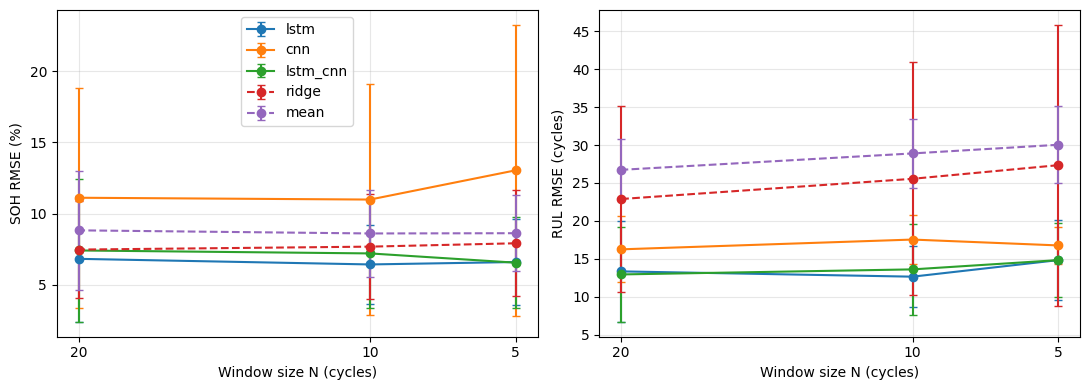

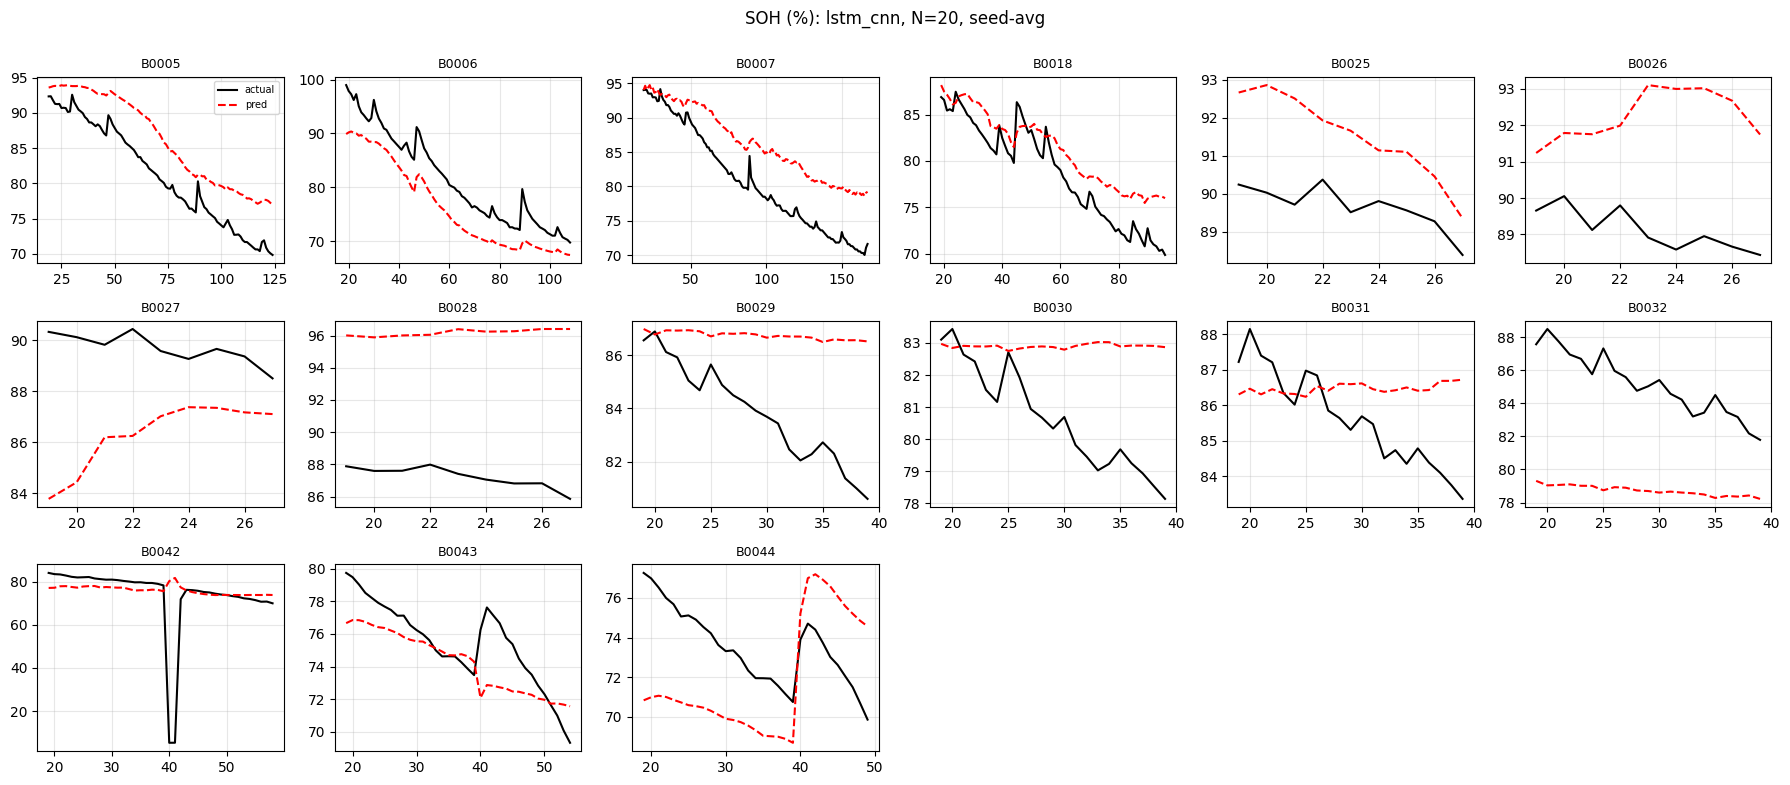

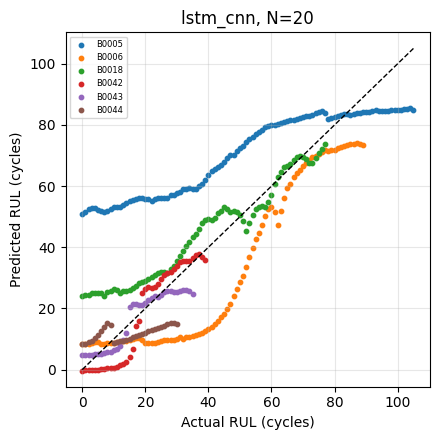

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os, re, glob; sys.path.insert(0, '/content/drive/MyDrive')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soh_train import metrics

OUT = '/content/drive/MyDrive/soh_results'
os.makedirs(OUT + '/figs', exist_ok=True)

# ---- load all saved predictions ----
pat = re.compile(r'^(.*)_N(\d+)_f(\d+)_s(\d+)$')
dfs = []
for f in glob.glob(OUT + '/preds/*.csv'):
    m = pat.match(os.path.basename(f)[:-4])
    d = pd.read_csv(f)
    d['model'], d['N'], d['fold'], d['seed'] = m[1], int(m[2]), int(m[3]), int(m[4])
    dfs.append(d)
P = pd.concat(dfs, ignore_index=True)
print(len(dfs), 'prediction files loaded')

# ---- per-battery errors (seeds averaged) ----
rows = []
for (mod, N, b, s), g in P.groupby(['model', 'N', 'battery_id', 'seed']):
    v = g[g.rul_valid]
    ms, mr = metrics(g.soh_true, g.soh_pred), metrics(v.rul_true, v.rul_pred)
    rows.append(dict(model=mod, N=N, battery=b, seed=s, n_cycles=len(g),
                     soh_rmse=ms['rmse'], soh_mae=ms['mae'],
                     rul_rmse=mr['rmse'], rul_mae=mr['mae']))
PB = (pd.DataFrame(rows).groupby(['model', 'N', 'battery'], as_index=False)
        .mean(numeric_only=True).drop(columns='seed'))
PB.to_csv(OUT + '/per_battery.csv', index=False)

for N_show in (10,):
    for col in ('soh_rmse', 'rul_rmse'):
        print(f'\n{col}, N={N_show}')
        print(PB[PB.N == N_show].pivot_table(index='battery', columns='model',
                                             values=col).round(2).to_string())

# ---- plot 1: error vs window size (mean +/- std over folds) ----
R = pd.read_csv(OUT + '/results.csv')
PF = R.groupby(['model', 'N', 'fold'], as_index=False).mean(numeric_only=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (c, t) in zip(ax, [('soh_rmse', 'SOH RMSE (%)'), ('rul_rmse', 'RUL RMSE (cycles)')]):
    for mod in ['lstm', 'cnn', 'lstm_cnn', 'ridge', 'mean']:
        g = PF[PF.model == mod].groupby('N')[c].agg(['mean', 'std']).sort_index()
        a.errorbar(g.index, g['mean'], yerr=g['std'], marker='o', capsize=3, label=mod,
                   ls='--' if mod in ('ridge', 'mean') else '-')
    a.set_xticks([5, 10, 20]); a.invert_xaxis()
    a.set_xlabel('Window size N (cycles)'); a.set_ylabel(t); a.grid(alpha=.3)
ax[0].legend()
plt.tight_layout(); plt.savefig(OUT + '/figs/error_vs_window.png', dpi=200); plt.show()

# ---- plot 2: actual vs predicted SOH per battery ----
MODEL, N = 'lstm_cnn', 20          # change to inspect other models / windows
S = (P[(P.model == MODEL) & (P.N == N)]
     .groupby(['battery_id', 'cycle_idx'], as_index=False)
     .agg(soh_true=('soh_true', 'first'), soh_pred=('soh_pred', 'mean'),
          rul_true=('rul_true', 'first'), rul_pred=('rul_pred', 'mean'),
          rul_valid=('rul_valid', 'first')))
bats = sorted(S.battery_id.unique())
nc = 6; nr = int(np.ceil(len(bats) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(3 * nc, 2.6 * nr), squeeze=False)
for a in axs.ravel(): a.axis('off')
for a, b in zip(axs.ravel(), bats):
    g = S[S.battery_id == b].sort_values('cycle_idx')
    a.axis('on')
    a.plot(g.cycle_idx, g.soh_true, 'k-', label='actual')
    a.plot(g.cycle_idx, g.soh_pred, 'r--', label='pred')
    a.set_title(str(b), fontsize=9); a.grid(alpha=.3)
axs[0, 0].legend(fontsize=7)
fig.suptitle(f'SOH (%): {MODEL}, N={N}, seed-avg', y=1.0)
plt.tight_layout(); plt.savefig(OUT + f'/figs/soh_{MODEL}_N{N}.png', dpi=200); plt.show()

# ---- plot 3: RUL predicted vs actual (EOL batteries only) ----
v = S[S.rul_valid.astype(bool)]
fig, a = plt.subplots(figsize=(4.5, 4.5))
for b, g in v.groupby('battery_id'):
    a.scatter(g.rul_true, g.rul_pred, s=10, label=str(b))
lim = [0, max(v.rul_true.max(), v.rul_pred.max())]
a.plot(lim, lim, 'k--', lw=1)
a.set_xlabel('Actual RUL (cycles)'); a.set_ylabel('Predicted RUL (cycles)')
a.set_title(f'{MODEL}, N={N}'); a.legend(fontsize=6); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT + f'/figs/rul_{MODEL}_N{N}.png', dpi=200); plt.show()